# 03 — Customer RFM and Segmentation

Customer features, RFM scores, segments, and clustering.

## 1. RFM framework

Recency measures days since the last purchase; frequency measures distinct purchase invoices; monetary value measures net transaction line value.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = Path.cwd().parent

REPORTS = ROOT / "reports"
PROCESSED = ROOT / "data" / "processed"
FIGURES = REPORTS / "figures"

print("Project root:", ROOT)
print("Reports directory exists:", REPORTS.exists())
print("Processed data directory exists:", PROCESSED.exists())

Project root: C:\Users\tadij\Documents\retail-customer-intelligence-python
Reports directory exists: True
Processed data directory exists: True


## 2. Customer-level RFM data

In [2]:
rfm = pd.read_csv(REPORTS / "customer_rfm.csv")
scored = pd.read_csv(REPORTS / "customer_rfm_scored.csv")
segments = pd.read_csv(REPORTS / "customer_segments.csv")

print("Customers in RFM dataset:", len(rfm))
display(rfm.describe().T)
display(scored.head())

Customers in RFM dataset: 4339


,count,mean,std,min,25%,50%,75%,max
customer_id,4339.0,15299.936852,1721.889758,12346.0,13812.500,15299.00,16778.500,18287.00
frequency,4339.0,4.271952,7.705493,1.0,1.000,2.00,5.000,210.00
monetary,4339.0,1915.297777,8247.979285,-1165.3,299.675,654.92,1623.825,279489.02
positive_transaction_value,4339.0,2053.793018,8988.248381,0.0,307.245,674.45,1661.640,280206.02
recency_days,4339.0,93.041484,100.007757,1.0,18.000,51.00,142.500,374.00


## 3. Rule-based customer segments

,segment,customer_count,average_recency_days,average_purchase_frequency,average_monetary,median_monetary,customer_percentage
0,Other Customers,1157,53.261884,1.894555,601.096162,531.35,26.665130
1,Champions,913,12.865279,11.490690,6045.360460,2666.61,21.041715
2,Low-Activity Customers,787,229.914867,1.000000,213.737752,200.16,18.137820
3,Needs Attention,717,160.211994,2.748954,768.261731,649.50,16.524545
4,Loyal Customers,379,39.593668,5.794195,2017.127522,1253.36,8.734732
5,Recent Customers,237,19.405063,1.000000,321.000717,225.36,5.462088
6,High-Spending Customers,149,100.114094,4.442953,3597.120275,2949.12,3.433971


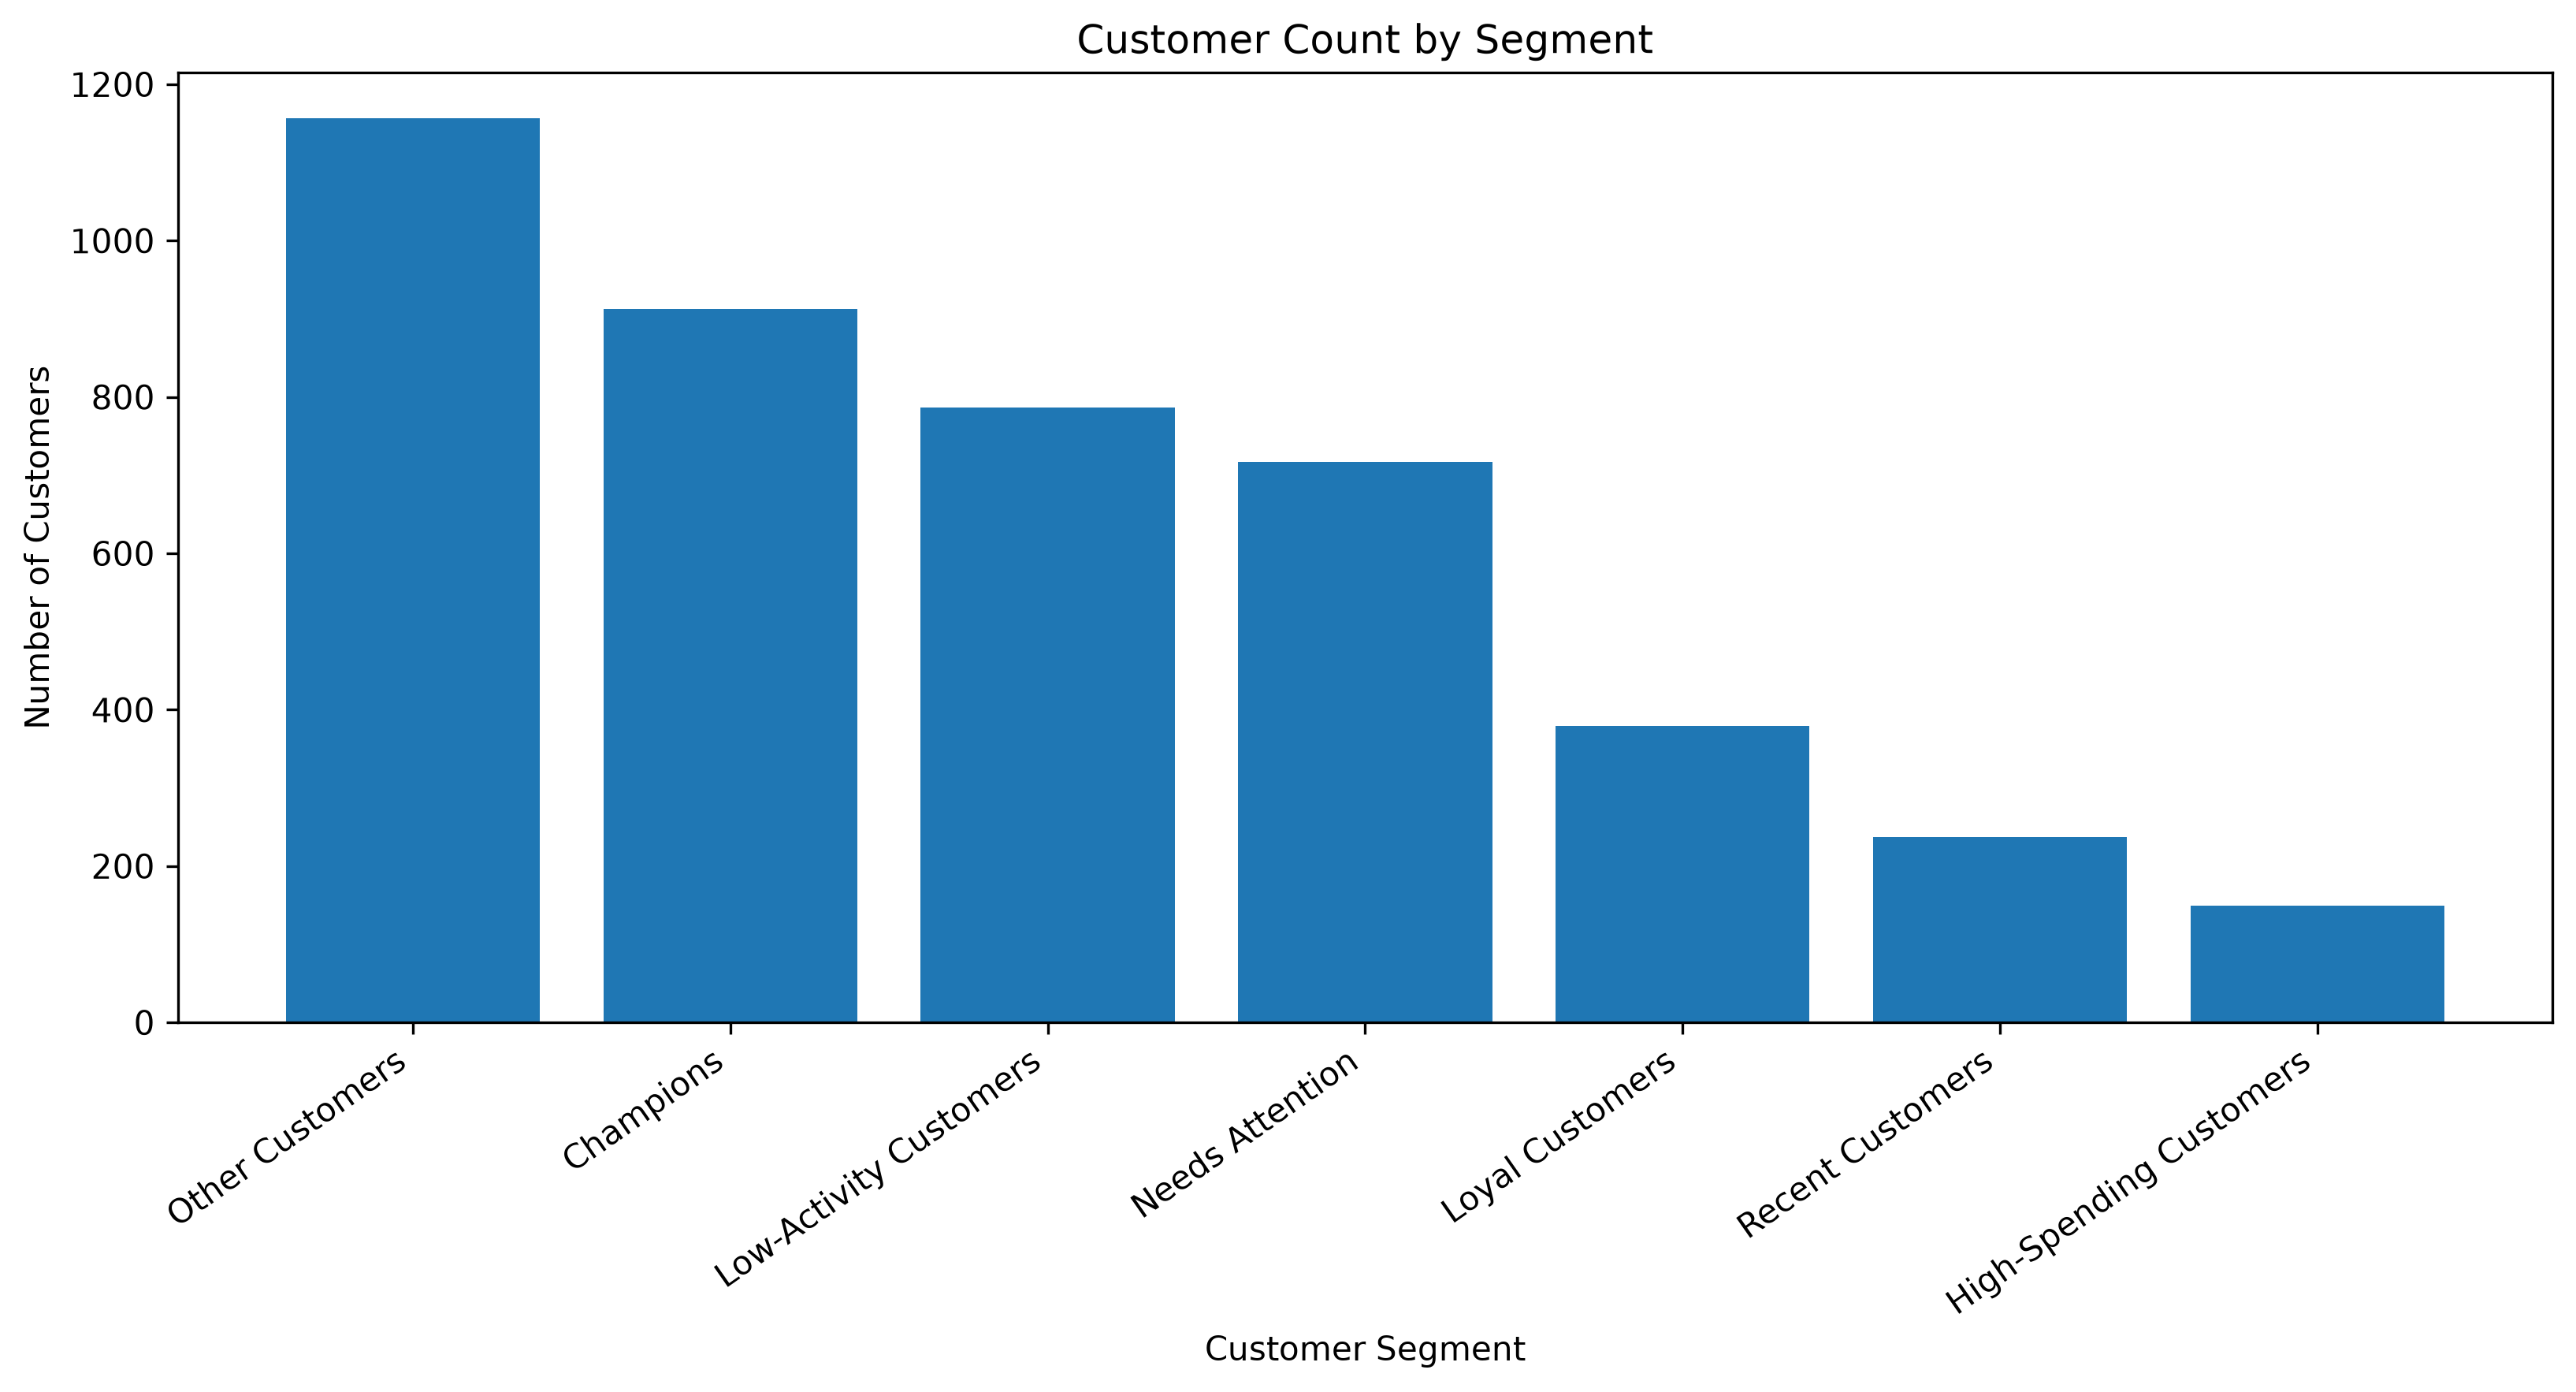

In [3]:
segment_summary = pd.read_csv(REPORTS / "customer_segment_summary.csv")
display(segment_summary)

segment_chart = FIGURES / "customer_count_by_segment.png"
if segment_chart.exists():
    from IPython.display import Image, display as show_image
    show_image(Image(filename=str(segment_chart)))

## 4. K-Means clustering comparison

In [4]:
evaluation_path = REPORTS / "clustering_model_evaluation.csv"
profiles_path = REPORTS / "customer_cluster_profiles.csv"

if evaluation_path.exists():
    display(pd.read_csv(evaluation_path))
if profiles_path.exists():
    display(pd.read_csv(profiles_path))

,n_clusters,inertia,silhouette_score,smallest_cluster_size,largest_cluster_size
0,2,9119.424463,0.392988,1749,2590
1,3,7082.098948,0.289586,896,1759
2,4,6135.697546,0.279693,840,1449
3,5,5296.938019,0.249194,497,1125
4,6,4798.649104,0.229961,317,1032
5,7,4403.647526,0.229793,287,848
6,8,4092.559717,0.225335,193,783


,cluster,customer_count,avg_recency_days,median_recency_days,avg_frequency,median_frequency,avg_positive_transaction_value,median_positive_transaction_value,avg_distinct_products,median_distinct_products,customer_percentage
0,0,2590,135.134749,96.0,1.641313,1.0,517.314252,352.18,25.435521,20.0,59.691173
1,1,1749,30.707833,18.0,8.167524,5.0,4329.081756,1981.92,115.294454,89.0,40.308827


## 5. Interpretation and limitations

RFM segments are rule-based, while K-Means groups customers according to scaled behavioral features. Cluster labels are arbitrary. Inactivity is not confirmed churn, and the short observation window limits lifecycle conclusions.